# Portafolio de Big Data: delitos reportados en Chicago

**Autor:** José Eduardo Pérez Abundiz · **Matrícula:** A01666860  
**Tecnologías:** PySpark MLlib y Tableau Public · **Fecha:** 6 de noviembre de 2026

## Pregunta del proyecto

¿Cuántos delitos se reportarán el próximo mes en cada distrito de Chicago, tomando como referencia los reportes del mes anterior, el mismo mes del año previo y el calendario?

**Alcance.** Se trabaja con un archivo CSV de **1.28 GB y 5,180,000 registros**, obtenido del [portal oficial de datos de Chicago](https://data.cityofchicago.org/Public-Safety/Crimes-2001-to-Present/ijzp-q8t2). Para el análisis se emplean los reportes de **2001 a 2012**. El modelo es una **regresión** que estima el total mensual por distrito; no predice incidentes individuales.

**Ruta de lectura:** configuración → validación del archivo → exploración → preparación → validación cruzada temporal → evaluación → tablero.


## 1. Preparación del entorno

La ejecución original se hizo localmente con Python 3.14.7 y PySpark 4.2.0. La celda siguiente crea una sesión Spark y muestra las versiones para documentar la reproducibilidad. En Google Colab, el directorio del proyecto debe contener la carpeta `datos` antes de ejecutar el procesamiento.


In [1]:
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

try:
    version_instalada = version("pyspark")
except PackageNotFoundError:
    version_instalada = None

if version_instalada != "4.2.0":
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "pyspark==4.2.0"],
        check=True
    )

from pyspark.sql import SparkSession
import pyspark

spark = (
    SparkSession.builder
    .appName("Portafolio_Delitos_Chicago")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Python:", sys.version.split()[0])
print("PySpark:", pyspark.__version__)
print("Spark activo:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/06 21:36:30 WARN Utils: Your hostname, MacBook-Air-de-Edu-2.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.69 instead (on interface en0)
26/11/06 21:36:30 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/Users/eduardoabundiz/Desktop/Portafolio_Chicago/.venv/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/06 21:36:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Python: 3.14.7
PySpark: 4.2.0
Spark activo: 4.2.0


Instalamos Matplotlib antes de generar figuras. Si ya está instalado, esta celda se ejecuta rápidamente.

In [2]:
%pip install -q matplotlib


Note: you may need to restart the kernel to use updated packages.


Definimos una sola ruta base. En el equipo donde se desarrolló el proyecto apunta a la carpeta original; en otro entorno se usa la carpeta de trabajo actual. Esto evita depender de la ubicación del archivo `.ipynb`.

In [3]:
from pathlib import Path

ruta_local = Path('/Users/eduardoabundiz/Desktop/Portafolio_Chicago')
RAIZ_PROYECTO = ruta_local if ruta_local.exists() else Path.cwd()
print('Carpeta del proyecto:', RAIZ_PROYECTO)


Carpeta del proyecto: /Users/eduardoabundiz/Desktop/Portafolio_Chicago


## 2. Fuente y comprobación de lectura

El conjunto proviene de *Crimes - 2001 to Present*, publicado por la ciudad de Chicago. Primero se descarga una muestra de 10,000 registros para revisar columnas y tipos. Los campos de texto pueden contener saltos de línea, por lo que la lectura CSV usa `multiLine=True`.


In [4]:
from pathlib import Path
from urllib.request import Request, urlopen
import shutil

carpeta_datos = RAIZ_PROYECTO / "datos"
carpeta_datos.mkdir(exist_ok=True)

archivo_muestra = carpeta_datos / "chicago_muestra_10000.csv"
url = "https://data.cityofchicago.org/resource/ijzp-q8t2.csv?$limit=10000"

if not archivo_muestra.exists():
    solicitud = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(solicitud, timeout=60) as respuesta:
        with open(archivo_muestra, "wb") as destino:
            shutil.copyfileobj(respuesta, destino)

df_muestra = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("multiLine", True)
    .csv(str(archivo_muestra))
)

print("Archivo:", archivo_muestra)
print("Tamaño (MB):", round(archivo_muestra.stat().st_size / 1_000_000, 2))
print("Registros:", df_muestra.count())
print("Columnas:", len(df_muestra.columns))

df_muestra.select(
    "date", "primary_type", "district", "community_area", "arrest"
).show(5, truncate=False)

df_muestra.printSchema()

Archivo: /Users/eduardoabundiz/Desktop/Portafolio_Chicago/datos/chicago_muestra_10000.csv
Tamaño (MB): 2.89
Registros: 10000
Columnas: 22
+-------------------+-----------------+--------+--------------+------+
|date               |primary_type     |district|community_area|arrest|
+-------------------+-----------------+--------+--------------+------+
|2026-10-29 00:00:00|THEFT            |19      |3             |false |
|2026-10-29 00:00:00|THEFT            |18      |7             |false |
|2026-10-29 00:00:00|THEFT            |3       |42            |false |
|2026-10-29 00:00:00|WEAPONS VIOLATION|5       |50            |true  |
|2026-10-29 00:00:00|CRIMINAL DAMAGE  |22      |73            |false |
+-------------------+-----------------+--------+--------------+------+
only showing top 5 rows
root
 |-- id: integer (nullable = true)
 |-- case_number: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- block: string (nullable = true)
 |-- iucr: string (nullable = true)
 |--

## 3. Archivo de gran volumen

La API pública se consultó por lotes de 20,000 filas, ordenados por `id`, y el avance se guardó en `descarga_chicago_estado.json`. El archivo se cerró después de superar **1 GB**. Esta es una extracción parcial por orden de identificador, por lo que **no representa de forma uniforme todos los años** del portal. La celda es reanudable y omite nuevas descargas si el archivo existente ya cumple el tamaño solicitado.

> La primera descarga puede tardar bastante. En una segunda ejecución se reutilizan el CSV y el archivo de estado.


In [5]:
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import Request, urlopen
import csv
import io
import json
import time

carpeta_datos = RAIZ_PROYECTO / "datos"
carpeta_datos.mkdir(exist_ok=True)

archivo_completo = carpeta_datos / "chicago_completo_sin_location.csv"
archivo_estado = carpeta_datos / "descarga_chicago_estado.json"

columnas = (
    "id,case_number,date,block,iucr,primary_type,description,"
    "location_description,arrest,domestic,beat,district,ward,"
    "community_area,fbi_code,x_coordinate,y_coordinate,year,"
    "updated_on,latitude,longitude"
)

if archivo_estado.exists():
    estado = json.loads(archivo_estado.read_text())
    with open(archivo_completo, "r+b") as archivo:
        archivo.truncate(estado["bytes"])
else:
    if archivo_completo.exists():
        raise RuntimeError(
            "Ya existe un CSV sin archivo de estado. Revísalo antes de reiniciar."
        )
    estado = {"ultimo_id": 0, "registros": 0, "bytes": 0}
    archivo_completo.touch()

lotes = 0

while archivo_completo.stat().st_size < 1_000_000_000:
    parametros = urlencode({
        "$select": columnas,
        "$where": f"id > {estado['ultimo_id']}",
        "$order": "id",
        "$limit": 20000,
    })
    url = f"https://data.cityofchicago.org/resource/ijzp-q8t2.csv?{parametros}"

    for intento in range(5):
        try:
            solicitud = Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urlopen(solicitud, timeout=90) as respuesta:
                contenido = respuesta.read()
            break
        except Exception:
            if intento == 4:
                raise
            time.sleep(2 ** intento)

    filas = list(csv.reader(io.StringIO(contenido.decode("utf-8-sig"))))
    cantidad = len(filas) - 1

    if cantidad == 0:
        break

    datos_a_guardar = (
        contenido if estado["registros"] == 0
        else contenido.split(b"\n", 1)[1]
    )

    with open(archivo_completo, "ab") as archivo:
        archivo.write(datos_a_guardar)

    estado["ultimo_id"] = int(filas[-1][0])
    estado["registros"] += cantidad
    estado["bytes"] = archivo_completo.stat().st_size

    temporal = archivo_estado.with_suffix(".tmp")
    temporal.write_text(json.dumps(estado))
    temporal.replace(archivo_estado)

    lotes += 1
    if lotes % 10 == 0:
        print(
            f"{estado['registros']:,} registros | "
            f"{estado['bytes'] / 1_000_000_000:.2f} GB"
        )

    if cantidad < 20000:
        break

tamano_gb = archivo_completo.stat().st_size / 1_000_000_000
print("\nARCHIVO DISPONIBLE")
print("Archivo:", archivo_completo)
print("Registros:", f"{estado['registros']:,}")
print("Tamaño exacto:", f"{tamano_gb:.3f} GB")
print("Cumple ≥1 GB:", archivo_completo.stat().st_size >= 1_000_000_000)


ARCHIVO DISPONIBLE
Archivo: /Users/eduardoabundiz/Desktop/Portafolio_Chicago/datos/chicago_completo_sin_location.csv
Registros: 5,180,000
Tamaño exacto: 1.280 GB
Cumple ≥1 GB: True


Comprobamos el tamaño exacto y el número de registros registrados durante la descarga. El requisito se refiere al **CSV original**, no al archivo resumido que se usa después en Tableau.

In [6]:
from pathlib import Path
import json

carpeta = RAIZ_PROYECTO / "datos"
archivo = carpeta / "chicago_completo_sin_location.csv"
estado = json.loads(
    (carpeta / "descarga_chicago_estado.json").read_text()
)

print("Registros guardados:", f"{estado['registros']:,}")
print("Tamaño exacto (GB):", round(archivo.stat().st_size / 1_000_000_000, 3))
print("Cumple ≥1 GB:", archivo.stat().st_size >= 1_000_000_000)

Registros guardados: 5,180,000
Tamaño exacto (GB): 1.28
Cumple ≥1 GB: True


## 4. Exploración y selección del período

Spark lee el archivo completo sin cargar sus 1.28 GB en pandas. Al contar por año observamos que el bloque continuo está concentrado en 2001–2012. Los años posteriores tienen cobertura parcial; incluirlos alteraría la comparación temporal. Por ello se selecciona 2001–2012 y se agregan los registros por mes y distrito.


In [7]:
from pyspark.sql import functions as F

df_crimenes = (
    spark.read
    .option("header", True)
    .csv(str(archivo))
    .withColumn("fecha", F.to_timestamp("date"))
)

conteos_por_anio = (
    df_crimenes
    .groupBy(F.year("fecha").alias("anio"))
    .count()
    .orderBy("anio")
    .collect()
)

registros_spark = sum(fila["count"] for fila in conteos_por_anio)

print("Columnas:", len(df_crimenes.columns))
print("Registros leídos por Spark:", f"{registros_spark:,}")
print("Coincide con la descarga:", registros_spark == estado["registros"])
print("\nRegistros por año:")

for fila in conteos_por_anio:
    print(fila["anio"], f"{fila['count']:,}")

Columnas: 22
Registros leídos por Spark: 5,180,000
Coincide con la descarga: True

Registros por año:
2001 485,630
2002 486,662
2003 475,811
2004 469,222
2005 453,450
2006 447,790
2007 436,566
2008 426,556
2009 392,069
2010 369,482
2011 350,606
2012 333,315
2013 45,032
2014 427
2015 496
2016 786
2017 672
2018 588
2019 499
2020 788
2021 806
2022 730
2023 632
2024 593
2025 436
2026 356


In [8]:
df_historico = (
    df_crimenes
    .filter(F.year("fecha").between(2001, 2012))
    .filter(F.col("district").isNotNull())
    .filter(F.col("district") != "")
    .select(
        F.date_trunc("month", F.col("fecha")).cast("date").alias("mes"),
        F.col("district").alias("distrito"),
        F.col("primary_type").alias("tipo_delito")
    )
)

df_mensual = (
    df_historico
    .groupBy("mes", "distrito")
    .agg(F.count("*").alias("reportes"))
    .cache()
)

resumen = df_mensual.agg(
    F.sum("reportes").alias("registros_utilizados"),
    F.countDistinct("mes").alias("meses"),
    F.countDistinct("distrito").alias("distritos"),
    F.min("mes").alias("primer_mes"),
    F.max("mes").alias("ultimo_mes")
)

resumen.show(truncate=False)
df_mensual.orderBy("mes", "distrito").show(8, truncate=False)

+--------------------+-----+---------+----------+----------+
|registros_utilizados|meses|distritos|primer_mes|ultimo_mes|
+--------------------+-----+---------+----------+----------+
|5127113             |144  |24       |2001-01-01|2012-12-01|
+--------------------+-----+---------+----------+----------+

+----------+--------+--------+
|mes       |distrito|reportes|
+----------+--------+--------+
|2001-01-01|001     |1297    |
|2001-01-01|002     |3096    |
|2001-01-01|003     |1831    |
|2001-01-01|004     |1937    |
|2001-01-01|005     |1421    |
|2001-01-01|006     |1979    |
|2001-01-01|007     |1890    |
|2001-01-01|008     |2433    |
+----------+--------+--------+
only showing top 8 rows


### Cobertura y tendencia

La serie mensual permite ver **estacionalidad** y una **disminución general de reportes** hacia 2012. La cobertura por distrito también revela dos distritos con muy pocos meses de datos: `021` y `031`. Para entrenar una serie comparable se conservan únicamente los 22 distritos con los 144 meses completos. La gráfica usa solo 144 puntos agregados; el procesamiento pesado permanece en Spark.


Cobertura por distrito:
+--------+---------------+----------------+
|distrito|meses_con_datos|reportes_totales|
+--------+---------------+----------------+
|021     |4              |4               |
|031     |79             |143             |
|001     |144            |183883          |
|002     |144            |251879          |
|003     |144            |264439          |
|004     |144            |289855          |
|005     |144            |227264          |
|006     |144            |290596          |
|007     |144            |308354          |
|008     |144            |354700          |
|009     |144            |260211          |
|010     |144            |213928          |
|011     |144            |316143          |
|012     |144            |252371          |
|014     |144            |208442          |
|015     |144            |225540          |
|016     |144            |167715          |
|017     |144            |149564          |
|018     |144            |218402          |
|019    

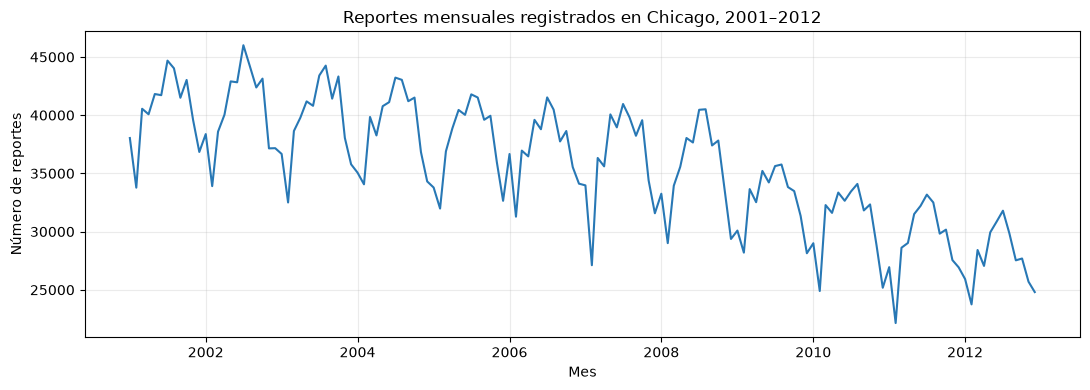

In [9]:
import matplotlib.pyplot as plt

cobertura = (
    df_mensual
    .groupBy("distrito")
    .agg(
        F.countDistinct("mes").alias("meses_con_datos"),
        F.sum("reportes").alias("reportes_totales")
    )
    .orderBy("meses_con_datos", "distrito")
)

print("Cobertura por distrito:")
cobertura.show(30, truncate=False)

totales_mensuales = (
    df_mensual
    .groupBy("mes")
    .agg(F.sum("reportes").alias("reportes"))
    .orderBy("mes")
    .collect()
)

plt.figure(figsize=(11, 4))
plt.plot(
    [fila["mes"] for fila in totales_mensuales],
    [fila["reportes"] for fila in totales_mensuales],
    color="#2878B5"
)
plt.title("Reportes mensuales registrados en Chicago, 2001–2012")
plt.xlabel("Mes")
plt.ylabel("Número de reportes")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Tipos de delito más frecuentes

La siguiente figura resume las diez categorías con más reportes en el período analizado. Cada barra corresponde al total de reportes de una categoría; las categorías no representan tasas por población. La agregación se realiza en Spark y solo diez valores pasan a Matplotlib.


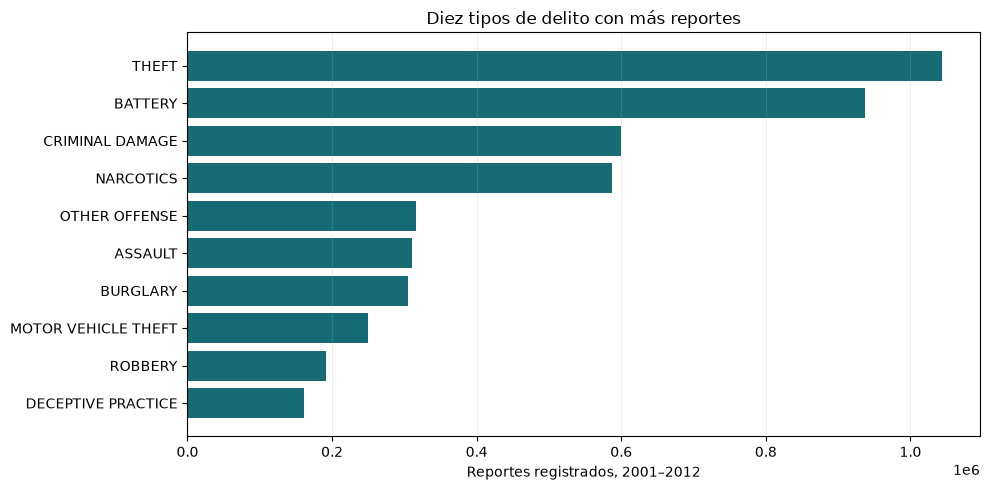

In [10]:
tipos_principales = (
    df_historico
    .groupBy('tipo_delito')
    .agg(F.count('*').alias('reportes'))
    .orderBy(F.desc('reportes'))
    .limit(10)
    .collect()
)

categorias = [fila['tipo_delito'] or 'SIN CLASIFICAR' for fila in tipos_principales]
valores = [fila['reportes'] for fila in tipos_principales]

plt.figure(figsize=(10, 5))
plt.barh(categorias[::-1], valores[::-1], color='#166B75')
plt.xlabel('Reportes registrados, 2001–2012')
plt.title('Diez tipos de delito con más reportes')
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


## 5. Construcción de variables

Cada fila del modelo representa **un mes de un distrito**. La variable a estimar es `reportes`. Como entradas usamos `mes_anterior`, `mismo_mes_anio_anterior`, número de mes, año y distrito. Los dos rezagos se calculan dentro de cada distrito para evitar mezclar series. El rezago de 12 meses elimina los primeros 12 meses y deja **2,904 filas** de 2002–2012.

**Interpretación operativa:** este modelo estima el mes actual cuando ya se conocen los totales del mes previo y del mismo mes del año anterior. No se debe usar para afirmar pronósticos a varios meses sin actualizar esos valores.


In [11]:
from pyspark.sql.window import Window

distritos_completos = (
    cobertura
    .filter(F.col("meses_con_datos") == 144)
    .select("distrito")
)

df_series = df_mensual.join(
    distritos_completos, on="distrito", how="inner"
)

ventana = Window.partitionBy("distrito").orderBy("mes")

df_modelo = (
    df_series
    .withColumn("mes_anterior", F.lag("reportes", 1).over(ventana))
    .withColumn("mismo_mes_anio_anterior", F.lag("reportes", 12).over(ventana))
    .filter(F.col("mismo_mes_anio_anterior").isNotNull())
    .withColumn("anio", F.year("mes"))
    .withColumn("numero_mes", F.month("mes"))
    .cache()
)

df_modelo.agg(
    F.count("*").alias("filas_para_modelar"),
    F.countDistinct("distrito").alias("distritos"),
    F.min("mes").alias("primer_mes"),
    F.max("mes").alias("ultimo_mes")
).show(truncate=False)

df_modelo.orderBy("distrito", "mes").show(5, truncate=False)

+------------------+---------+----------+----------+
|filas_para_modelar|distritos|primer_mes|ultimo_mes|
+------------------+---------+----------+----------+
|2904              |22       |2002-01-01|2012-12-01|
+------------------+---------+----------+----------+

+--------+----------+--------+------------+-----------------------+----+----------+
|distrito|mes       |reportes|mes_anterior|mismo_mes_anio_anterior|anio|numero_mes|
+--------+----------+--------+------------+-----------------------+----+----------+
|001     |2002-01-01|1519    |1118        |1297                   |2002|1         |
|001     |2002-02-01|1404    |1519        |1120                   |2002|2         |
|001     |2002-03-01|1367    |1404        |1332                   |2002|3         |
|001     |2002-04-01|1485    |1367        |1206                   |2002|4         |
|001     |2002-05-01|1512    |1485        |1174                   |2002|5         |
+--------+----------+--------+------------+-------------------

## 6. Separación temporal y referencia

Entrenamiento: **2002–2010** (2,376 filas). Prueba final: **2011–2012** (528 filas). El conjunto de prueba se reserva hasta haber elegido los hiperparámetros. Como punto de comparación simple, predecimos que cada distrito tendrá el mismo número de reportes que en el mes anterior. Una separación aleatoria mezclaría pasado y futuro, por eso la división respeta el calendario.


In [12]:
df_entrenamiento = df_modelo.filter(F.col("anio") <= 2010)
df_prueba = df_modelo.filter(F.col("anio") >= 2011)

print("Filas de entrenamiento (2002–2010):", df_entrenamiento.count())
print("Filas de prueba (2011–2012):", df_prueba.count())

df_prueba.agg(
    F.round(
        F.avg(F.abs(F.col("reportes") - F.col("mes_anterior"))),
        2
    ).alias("error_medio_mes_anterior"),
    F.round(
        F.avg(F.abs(
            F.col("reportes") - F.col("mismo_mes_anio_anterior")
        )),
        2
    ).alias("error_medio_mismo_mes_anio_anterior")
).show(truncate=False)

Filas de entrenamiento (2002–2010): 2376
Filas de prueba (2011–2012): 528
+------------------------+-----------------------------------+
|error_medio_mes_anterior|error_medio_mismo_mes_anio_anterior|
+------------------------+-----------------------------------+
|102.13                  |105.14                             |
+------------------------+-----------------------------------+



## 7. Pipeline de MLlib

El pipeline aplica `StringIndexer` y `OneHotEncoder` al distrito, reúne las variables con `VectorAssembler` y entrena un `RandomForestRegressor`. Esta secuencia encapsula la preparación y el modelo en un solo objeto. La prueba inicial sobre 2008 verifica que el procedimiento funcione y supere la referencia básica antes de explorar parámetros.


In [13]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

def crear_pipeline(profundidad=5, arboles=30):
    indice_distrito = StringIndexer(
        inputCol="distrito",
        outputCol="distrito_indice",
        handleInvalid="keep"
    )

    codificador_distrito = OneHotEncoder(
        inputCols=["distrito_indice"],
        outputCols=["distrito_vector"]
    )

    variables = VectorAssembler(
        inputCols=[
            "mes_anterior",
            "mismo_mes_anio_anterior",
            "numero_mes",
            "anio",
            "distrito_vector"
        ],
        outputCol="features"
    )

    bosque = RandomForestRegressor(
        featuresCol="features",
        labelCol="reportes",
        maxDepth=profundidad,
        numTrees=arboles,
        seed=42
    )

    return Pipeline(
        stages=[indice_distrito, codificador_distrito, variables, bosque]
    )

entrena_hasta_2007 = df_entrenamiento.filter(F.col("anio") <= 2007)
valida_2008 = df_entrenamiento.filter(F.col("anio") == 2008)

modelo_inicial = crear_pipeline().fit(entrena_hasta_2007)
predicciones_2008 = modelo_inicial.transform(valida_2008)

evaluador_mae = RegressionEvaluator(
    labelCol="reportes",
    predictionCol="prediction",
    metricName="mae"
)

print(
    "MAE del modelo en 2008:",
    round(evaluador_mae.evaluate(predicciones_2008), 2)
)

valida_2008.agg(
    F.round(
        F.avg(F.abs(F.col("reportes") - F.col("mes_anterior"))),
        2
    ).alias("MAE_referencia_2008")
).show()

predicciones_2008.select(
    "mes", "distrito", "reportes", "prediction"
).orderBy("mes", "distrito").show(5, truncate=False)

MAE del modelo en 2008: 89.94
+-------------------+
|MAE_referencia_2008|
+-------------------+
|             130.14|
+-------------------+

+----------+--------+--------+------------------+
|mes       |distrito|reportes|prediction        |
+----------+--------+--------+------------------+
|2008-01-01|001     |1195    |1327.9937401129005|
|2008-01-01|002     |1395    |1477.0219176996532|
|2008-01-01|003     |1654    |1651.5209775655553|
|2008-01-01|004     |1951    |1893.2970933750162|
|2008-01-01|005     |1605    |1499.9166114693303|
+----------+--------+--------+------------------+
only showing top 5 rows


## 8. Validación cruzada temporal

Se comparan cuatro configuraciones: profundidades **4 y 6**, con **20 y 40 árboles**. Para cada una se entrena con todos los años anteriores y se valida, por separado, en **2008, 2009 y 2010**. Este esquema de **ventana expansiva** es una validación cruzada temporal: utiliza tres particiones cronológicas y evita entrenar con datos futuros.

La configuración elegida se basa en el menor **MAE promedio** de los tres años de validación. El conjunto 2011–2012 no participa en esta elección.


In [14]:
resultados_cv = []

for profundidad in [4, 6]:
    for arboles in [20, 40]:
        errores = []

        for anio_validacion in [2008, 2009, 2010]:
            datos_entrenar = df_entrenamiento.filter(
                F.col("anio") < anio_validacion
            )
            datos_validar = df_entrenamiento.filter(
                F.col("anio") == anio_validacion
            )

            modelo = crear_pipeline(
                profundidad=profundidad,
                arboles=arboles
            ).fit(datos_entrenar)

            predicciones = modelo.transform(datos_validar)
            mae = evaluador_mae.evaluate(predicciones)
            errores.append(mae)

            print(
                f"Profundidad={profundidad}, árboles={arboles}, "
                f"validación={anio_validacion}: MAE={mae:.2f}",
                flush=True
            )

        resultados_cv.append({
            "profundidad": profundidad,
            "arboles": arboles,
            "mae_promedio": sum(errores) / len(errores)
        })

mejor_configuracion = min(
    resultados_cv,
    key=lambda resultado: resultado["mae_promedio"]
)

print("\nResultados promedio:")
for resultado in resultados_cv:
    print(resultado)

print("\nMejor configuración:", mejor_configuracion)

Profundidad=4, árboles=20, validación=2008: MAE=110.10
Profundidad=4, árboles=20, validación=2009: MAE=120.24
Profundidad=4, árboles=20, validación=2010: MAE=145.79
Profundidad=4, árboles=40, validación=2008: MAE=104.24
Profundidad=4, árboles=40, validación=2009: MAE=132.25
Profundidad=4, árboles=40, validación=2010: MAE=129.73
Profundidad=6, árboles=20, validación=2008: MAE=85.02
Profundidad=6, árboles=20, validación=2009: MAE=107.38
Profundidad=6, árboles=20, validación=2010: MAE=105.09
Profundidad=6, árboles=40, validación=2008: MAE=81.46
Profundidad=6, árboles=40, validación=2009: MAE=111.27
Profundidad=6, árboles=40, validación=2010: MAE=95.66

Resultados promedio:
{'profundidad': 4, 'arboles': 20, 'mae_promedio': 125.37627160848088}
{'profundidad': 4, 'arboles': 40, 'mae_promedio': 122.07472796643764}
{'profundidad': 6, 'arboles': 20, 'mae_promedio': 99.16530521855616}
{'profundidad': 6, 'arboles': 40, 'mae_promedio': 96.12802367356834}

Mejor configuración: {'profundidad': 6, 'a

**Resultado de la selección.** La profundidad 6 con 40 árboles obtuvo el mejor MAE promedio (**96.13 reportes**). Los errores de cada año variaron entre **81.46** y **111.27**, por lo que el resultado depende del período evaluado.


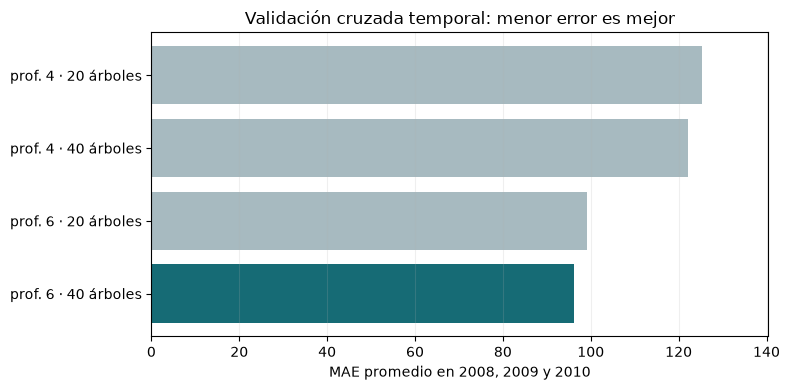

In [15]:
etiquetas = [
    f"prof. {r['profundidad']} · {r['arboles']} árboles"
    for r in resultados_cv
]
errores = [r['mae_promedio'] for r in resultados_cv]
colores = ['#166B75' if r == mejor_configuracion else '#A7BAC0' for r in resultados_cv]

plt.figure(figsize=(8, 4))
plt.barh(etiquetas[::-1], errores[::-1], color=colores[::-1])
plt.xlabel('MAE promedio en 2008, 2009 y 2010')
plt.title('Validación cruzada temporal: menor error es mejor')
plt.xlim(0, max(errores) * 1.12)
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


## 9. Evaluación final y predicciones

Se reentrena el pipeline elegido con todo 2002–2010 y se evalúa una sola vez sobre 2011–2012. **MAE** expresa el error absoluto medio en reportes, **RMSE** penaliza más los errores grandes y **R²** describe cuánto de la variación observada explica el modelo. El MAE se compara con la referencia del mes anterior para saber si el modelo añade valor.


In [16]:
modelo_final = crear_pipeline(
    profundidad=mejor_configuracion["profundidad"],
    arboles=mejor_configuracion["arboles"]
).fit(df_entrenamiento)

predicciones_prueba = (
    modelo_final
    .transform(df_prueba)
    .cache()
)

mae_final = RegressionEvaluator(
    labelCol="reportes",
    predictionCol="prediction",
    metricName="mae"
).evaluate(predicciones_prueba)

rmse_final = RegressionEvaluator(
    labelCol="reportes",
    predictionCol="prediction",
    metricName="rmse"
).evaluate(predicciones_prueba)

r2_final = RegressionEvaluator(
    labelCol="reportes",
    predictionCol="prediction",
    metricName="r2"
).evaluate(predicciones_prueba)

mae_referencia = df_prueba.agg(
    F.avg(
        F.abs(F.col("reportes") - F.col("mes_anterior"))
    ).alias("mae")
).first()["mae"]

print(f"MAE del modelo: {mae_final:.2f} reportes")
print(f"RMSE del modelo: {rmse_final:.2f} reportes")
print(f"R² del modelo: {r2_final:.3f}")
print(f"MAE de referencia: {mae_referencia:.2f} reportes")
print(
    "Mejora frente a la referencia:",
    f"{(mae_referencia - mae_final) / mae_referencia * 100:.1f}%"
)

predicciones_prueba.select(
    "mes",
    "distrito",
    "reportes",
    F.round("prediction", 0).alias("prediccion")
).orderBy("mes", "distrito").show(8, truncate=False)

MAE del modelo: 95.93 reportes
RMSE del modelo: 118.07 reportes
R² del modelo: 0.913
MAE de referencia: 102.13 reportes
Mejora frente a la referencia: 6.1%
+----------+--------+--------+----------+
|mes       |distrito|reportes|prediccion|
+----------+--------+--------+----------+
|2011-01-01|001     |893     |1026.0    |
|2011-01-01|002     |1213    |1148.0    |
|2011-01-01|003     |1423    |1423.0    |
|2011-01-01|004     |1618    |1486.0    |
|2011-01-01|005     |1250    |1161.0    |
|2011-01-01|006     |1457    |1576.0    |
|2011-01-01|007     |1515    |1664.0    |
|2011-01-01|008     |1948    |2112.0    |
+----------+--------+--------+----------+
only showing top 8 rows


El modelo logró **MAE 95.93**, **RMSE 118.07** y **R² 0.913**. La referencia tuvo **MAE 102.13**, de modo que la mejora fue **6.1 %**. Por ejemplo, para el distrito `001` en enero de 2011 se observaron **893** reportes y se estimaron **1,026**. Las predicciones sirven para analizar el volumen mensual, aunque el error puede ser relevante para distritos con pocos reportes.

La siguiente figura compara las 528 observaciones de prueba. La línea roja representa una estimación exacta; la distancia vertical de cada punto a la línea muestra su error.


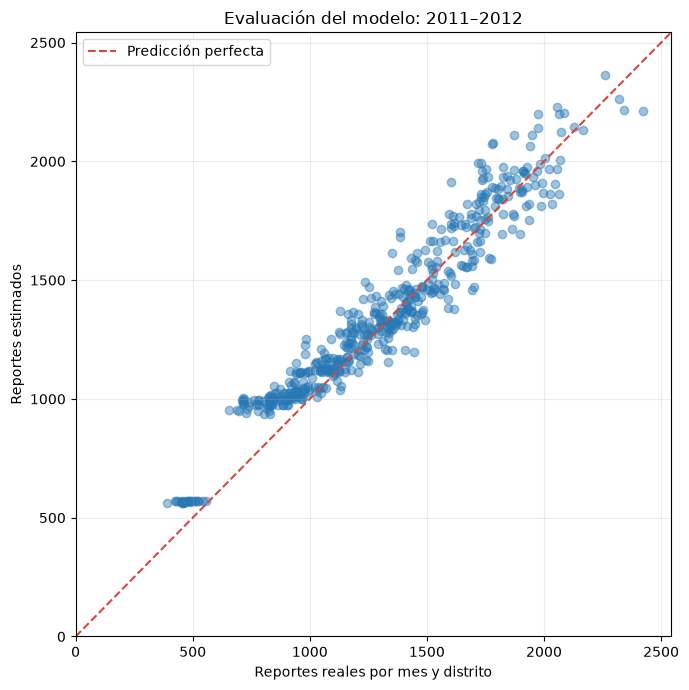

In [17]:
puntos = predicciones_prueba.select(
    "reportes", "prediction"
).collect()

reales = [fila["reportes"] for fila in puntos]
estimados = [fila["prediction"] for fila in puntos]
limite = max(max(reales), max(estimados)) * 1.05

plt.figure(figsize=(7, 7))
plt.scatter(reales, estimados, alpha=0.45, color="#2878B5")
plt.plot(
    [0, limite], [0, limite],
    linestyle="--", color="#D44A3A",
    label="Predicción perfecta"
)
plt.xlim(0, limite)
plt.ylim(0, limite)
plt.xlabel("Reportes reales por mes y distrito")
plt.ylabel("Reportes estimados")
plt.title("Evaluación del modelo: 2011–2012")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Datos para Tableau Public

El tablero necesita archivos pequeños y rápidos de explorar. Spark genera un resumen por mes, distrito y tipo de delito, y otro archivo con las 528 predicciones. El primero contiene **72,775 filas** que representan **5,127,113 reportes**. Este resumen es una salida derivada del CSV original de 1.28 GB.


In [18]:
from pathlib import Path
import csv
import shutil

carpeta_tableau = RAIZ_PROYECTO / "datos_para_tableau"
carpeta_tableau.mkdir(exist_ok=True)

df_tablero = (
    df_historico
    .withColumn(
        "tipo_delito",
        F.coalesce(F.col("tipo_delito"), F.lit("SIN CLASIFICAR"))
    )
    .groupBy("mes", "distrito", "tipo_delito")
    .agg(F.count("*").alias("reportes"))
    .withColumn(
        "distrito_etiqueta",
        F.concat(F.lit("Distrito "), F.col("distrito"))
    )
    .select("mes", "distrito_etiqueta", "tipo_delito", "reportes")
)

carpeta_temporal = carpeta_tableau / "_resumen_spark"

(
    df_tablero.coalesce(1)
    .write.mode("overwrite")
    .option("header", True)
    .csv(str(carpeta_temporal))
)

archivo_parte = next(carpeta_temporal.glob("part-*.csv"))
archivo_tableau = carpeta_tableau / "resumen_delitos_2001_2012.csv"

shutil.copy2(archivo_parte, archivo_tableau)
shutil.rmtree(carpeta_temporal)

filas_resumen = 0
reportes_resumen = 0

with open(archivo_tableau, newline="", encoding="utf-8") as archivo_csv:
    for fila in csv.DictReader(archivo_csv):
        filas_resumen += 1
        reportes_resumen += int(fila["reportes"])

print("Archivo:", archivo_tableau)
print("Filas resumidas:", f"{filas_resumen:,}")
print("Reportes representados:", f"{reportes_resumen:,}")
print(
    "Tamaño (MB):",
    round(archivo_tableau.stat().st_size / 1_000_000, 2)
)
print("Coincide con el análisis:", reportes_resumen == 5_127_113)

Archivo: /Users/eduardoabundiz/Desktop/Portafolio_Chicago/datos_para_tableau/resumen_delitos_2001_2012.csv
Filas resumidas: 72,775
Reportes representados: 5,127,113
Tamaño (MB): 3.02
Coincide con el análisis: True


In [19]:
df_predicciones_tableau = predicciones_prueba.select(
    "mes",
    F.concat(
        F.lit("Distrito "), F.col("distrito")
    ).alias("distrito_etiqueta"),
    F.col("reportes").alias("reportes_reales"),
    F.round("prediction", 0).cast("int").alias("reportes_estimados"),
    F.col("mes_anterior").alias("referencia_mes_anterior"),
    F.round(
        F.abs(F.col("reportes") - F.col("prediction")),
        2
    ).alias("error_absoluto")
)

carpeta_temporal_pred = carpeta_tableau / "_predicciones_spark"

(
    df_predicciones_tableau.coalesce(1)
    .write.mode("overwrite")
    .option("header", True)
    .csv(str(carpeta_temporal_pred))
)

archivo_parte_pred = next(carpeta_temporal_pred.glob("part-*.csv"))
archivo_predicciones = carpeta_tableau / "predicciones_2011_2012.csv"

shutil.copy2(archivo_parte_pred, archivo_predicciones)
shutil.rmtree(carpeta_temporal_pred)

with open(archivo_predicciones, newline="", encoding="utf-8") as archivo_csv:
    filas_predicciones = list(csv.DictReader(archivo_csv))

print("Archivo:", archivo_predicciones)
print("Predicciones exportadas:", len(filas_predicciones))
print("Primer mes:", min(fila["mes"] for fila in filas_predicciones))
print("Último mes:", max(fila["mes"] for fila in filas_predicciones))
print(
    "Tamaño (KB):",
    round(archivo_predicciones.stat().st_size / 1_000, 2)
)


Archivo: /Users/eduardoabundiz/Desktop/Portafolio_Chicago/datos_para_tableau/predicciones_2011_2012.csv
Predicciones exportadas: 528
Primer mes: 2011-01-01
Último mes: 2012-12-01
Tamaño (KB): 23.65


## 11. Tablero publicado

**[Abrir tablero interactivo en Tableau Public](https://public.tableau.com/views/DelitosenChicago2001-2012PySparkMLlib/DelitosenChicago2001-2012?:showVizHome=no)**

El tablero presenta el total de reportes, su evolución temporal, la distribución por tipo y distrito, y la comparación entre valores reales y estimados. La visualización del modelo usa color para distinguir la magnitud del error. Se publicó a partir de los dos CSV resumidos, no del archivo original de 1.28 GB.

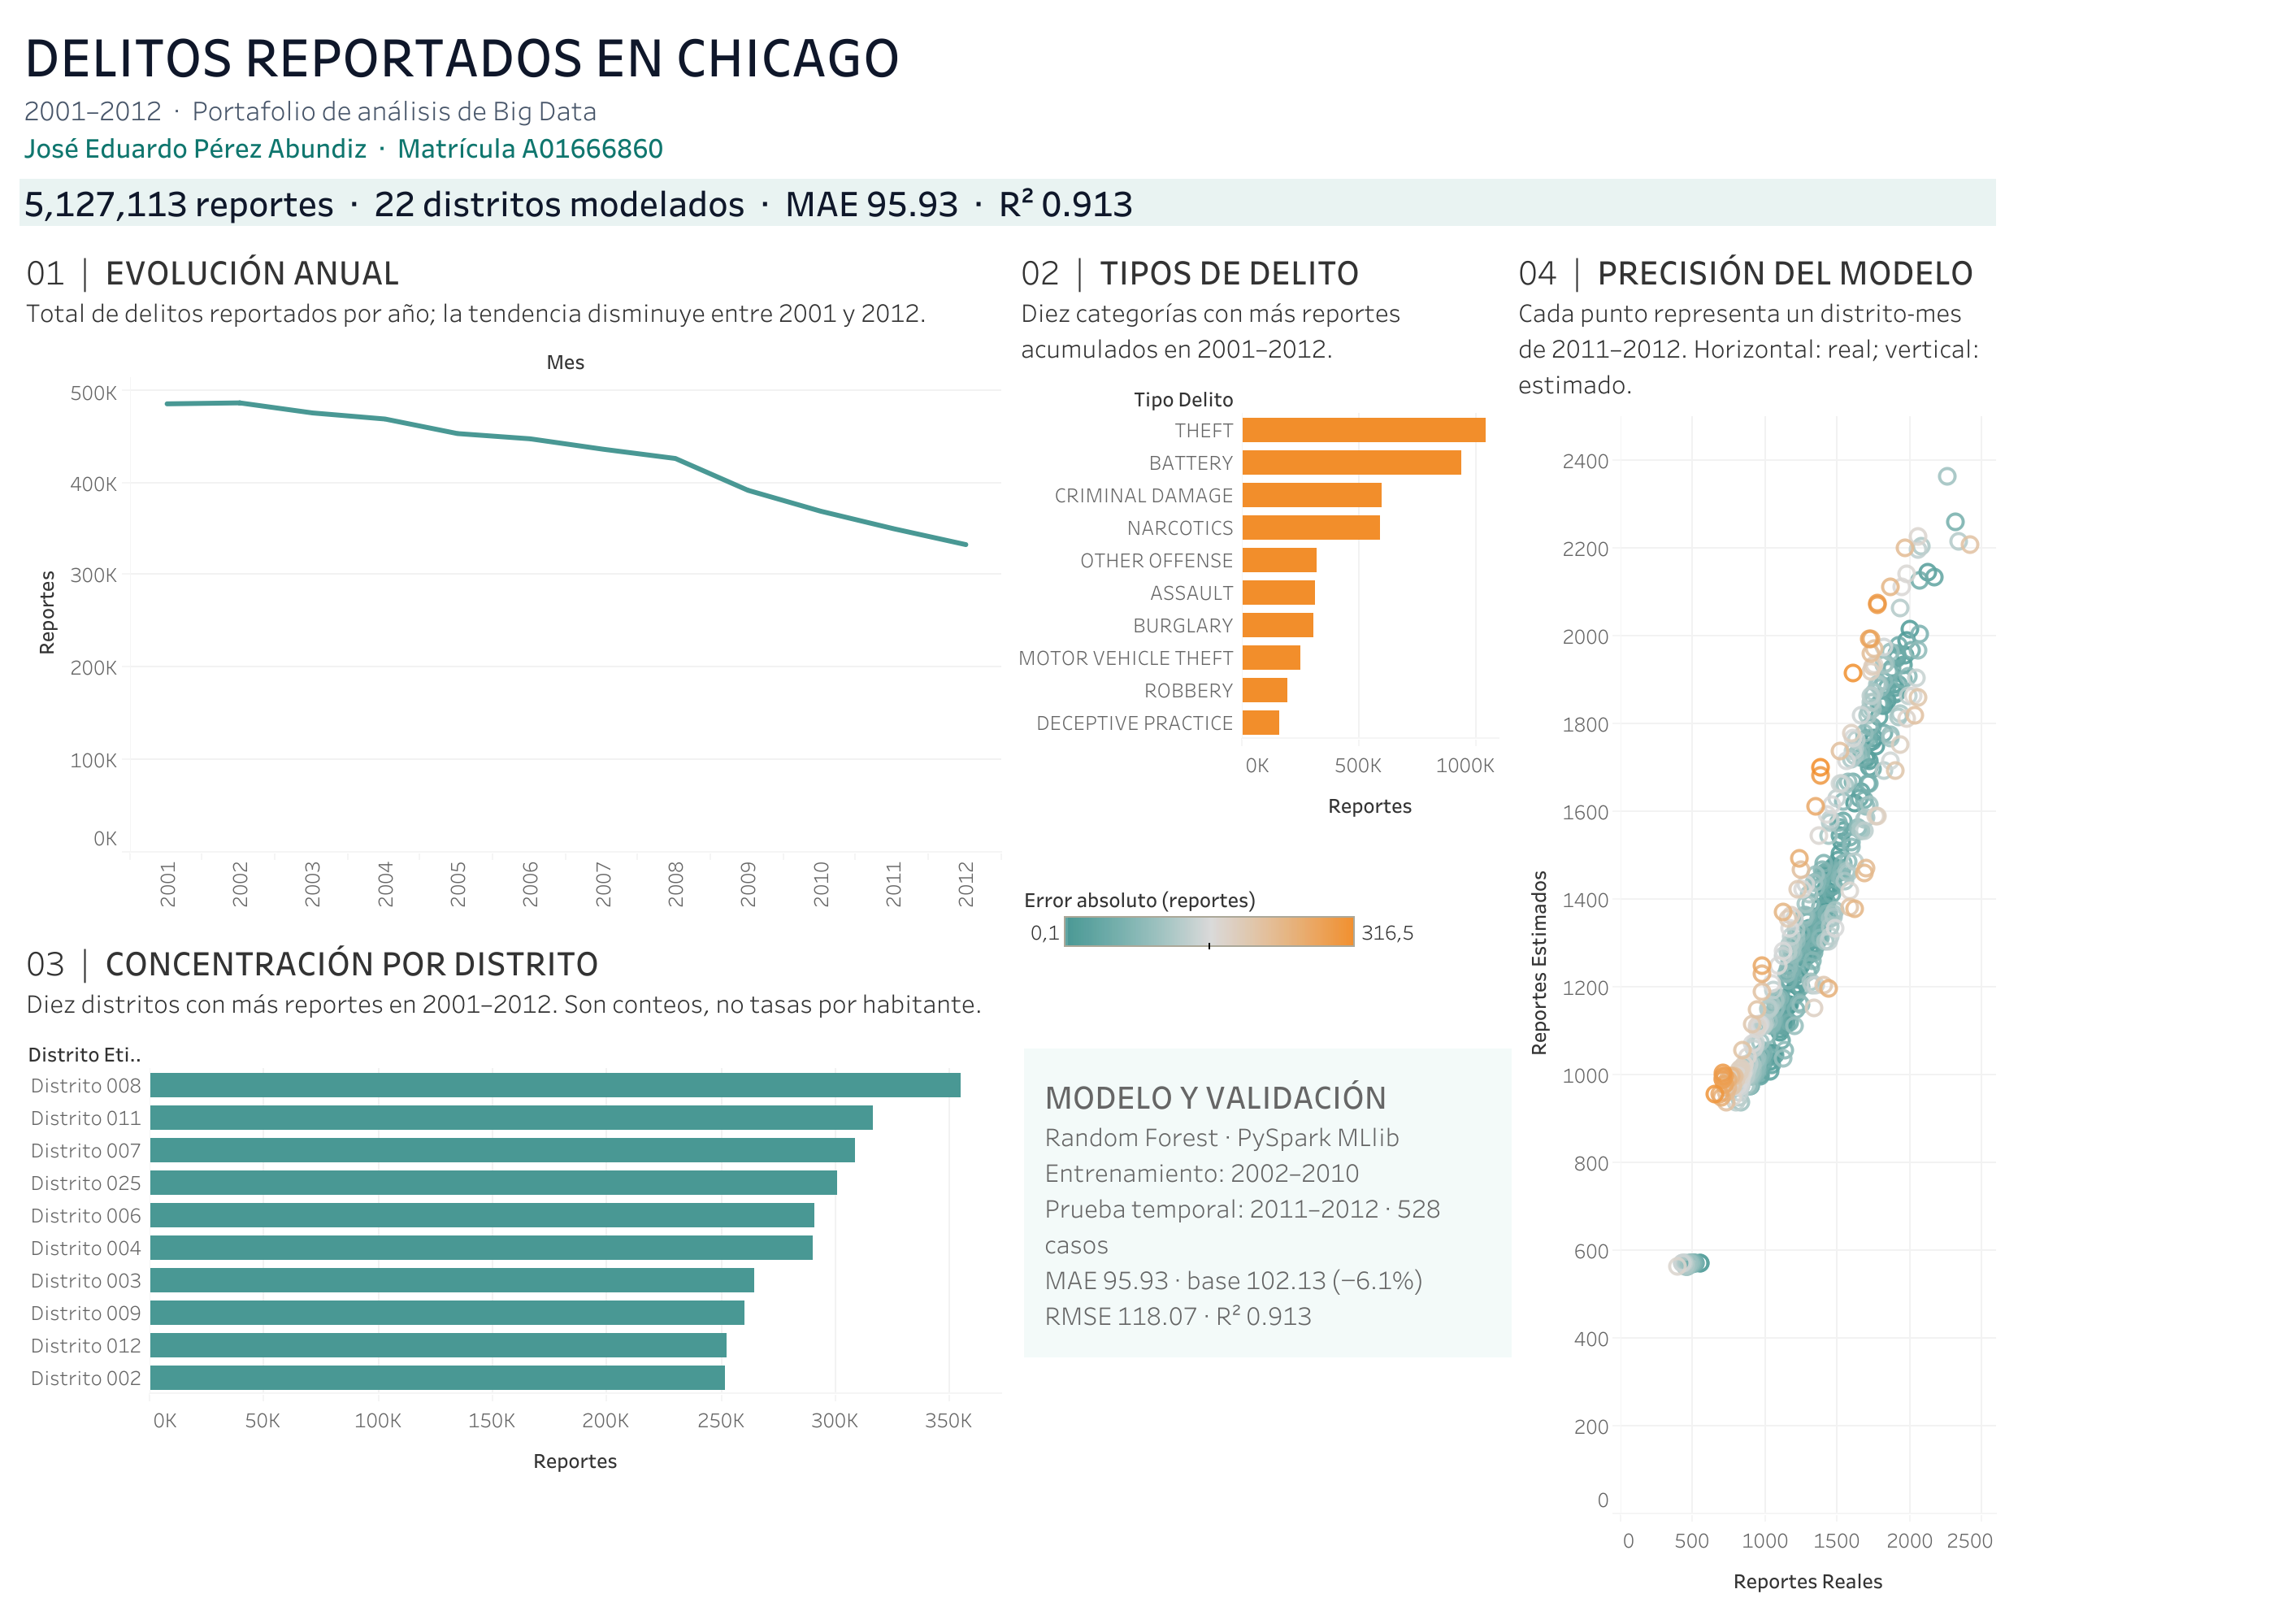


## 12. Conclusiones y límites

- Spark permitió leer y agregar **5.18 millones de filas** sin trasladar el archivo completo a pandas.
- El análisis empleó **5,127,113 reportes de 2001–2012**; el modelo se entrenó en **22 distritos con cobertura mensual completa**.
- La validación cruzada temporal seleccionó un bosque de **40 árboles y profundidad 6**. En 2011–2012 redujo el MAE de **102.13** a **95.93 reportes**, una mejora de **6.1 %** frente a la referencia.
- El archivo descargado es una **extracción parcial ordenada por ID**. Por eso los resultados describen este subconjunto histórico y no deben presentarse como una estimación de todos los delitos actuales de Chicago.
- Los datos abarcan reportes registrados; la calidad de la captura y los cambios de registro pueden afectar la serie. El modelo estima conteos mensuales, no causalidad ni riesgo individual.

**Fuente:** [City of Chicago, Crimes - 2001 to Present](https://data.cityofchicago.org/Public-Safety/Crimes-2001-to-Present/ijzp-q8t2). **Herramientas:** PySpark 4.2.0, MLlib, Matplotlib y Tableau Public.


## 13. Repositorio de la evidencia

Esta evidencia individual también se encuentra disponible en el repositorio del equipo Vacones:

[Ver la evidencia individual en GitHub](https://github.com/Vacones/Evidencias_BigData/tree/main/Individual/BigData_J.Eduardo_Perez_Abundiz_A01666860)